In [1]:
import xmlrpc.client
import pickle
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
from pylab import array, imshow

from datetime import datetime, timedelta

In [2]:
%matplotlib inline  
plt.rcParams['figure.figsize'] = (12, 12)

In [3]:
server = xmlrpc.client.ServerProxy("http://127.0.0.1:8008/RPC2")
stats_server = xmlrpc.client.ServerProxy("http://127.0.0.1:8018/RPC2")

In [4]:
print("Тестирование базовых функций")

print('\n1. Ping:', server.ping())
print('2. Server datetime:', server.now())

print('\n3. Тестирование типов данных:')
test_values = [
    2,                    # int
    2.,                   # float
    'My string',          # str
    [1, 2, 3],            # list
    (1, 2, "3"),          # tuple
]
for val in test_values:
    result = server.type(val)
    print(f'   Исходное: {val!r:15} ->    Тип на сервере: {result[1]}')


print('\n4. Математика:')
print(f'   Sum 2 + 3 = {server.sum(2, 3)}')
print(f'   Pow 2^3 = {server.pow(2, 3)}')

Тестирование базовых функций

1. Ping: True
2. Server datetime: 20261003T23:52:22

3. Тестирование типов данных:
   Исходное: 2               ->    Тип на сервере: <class 'int'>
   Исходное: 2.0             ->    Тип на сервере: <class 'float'>
   Исходное: 'My string'     ->    Тип на сервере: <class 'str'>
   Исходное: [1, 2, 3]       ->    Тип на сервере: <class 'list'>
   Исходное: (1, 2, '3')     ->    Тип на сервере: <class 'list'>

4. Математика:
   Sum 2 + 3 = 5
   Pow 2^3 = 8


In [5]:
print("Тестирование черного списка")

test_persons = [
    ("Иванов", "Иван", "Иванович", "22.03.1989"),
    ("Светлый", "Михаил", "Викторович", "13.02.1992"),
    ("Скалина", "Светлана", "Алексеевна", "19.11.1985"),
    
    ("ИВАНОВ", "иван", "Иванович", "22.03.1989"),
    ("петров", "ПЕТР", "петрович", "07.08.1985"),
    
    # Замена буквы
    ("Питров", "Петр", "Петрович", "07.08.1985"),
    ("Светлый", "Мехаил", "Викторович", "13.02.1992"),
    
    # Удаление буквы
    ("Склина", "Светлана", "Алексеевна", "19.11.1985"),
    
    # Транспозиция
    ("Дорбынин", "Виталий", "Александрович", "15.04.1985"),
    
    # Нет совпадений
    ("Сидоров", "Алексей", "Петрович", "01.01.2000"),
    ("Кузнецов", "Мария", "Сергеевна", "15.06.1995"),
    
    # Другая дата
    ("Иванов", "Иван", "Иванович", "01.01.1900"),
]

for surname, name, patronym, birth in test_persons:
    result = server.black_list_check(surname, name, patronym, birth)
    print(f'   {result}')

Тестирование черного списка
   Иванов Иван Иванович (22.03.1989): yes
   Светлый Михаил Викторович (13.02.1992): yes
   Скалина Светлана Алексеевна (19.11.1985): yes
   ИВАНОВ иван Иванович (22.03.1989): yes
   петров ПЕТР петрович (07.08.1985): yes
   Питров Петр Петрович (07.08.1985): similar [Петров Петр Петрович (07.08.1985)]
   Светлый Мехаил Викторович (13.02.1992): similar [Светлый Михаил Викторович (13.02.1992)]
   Склина Светлана Алексеевна (19.11.1985): similar [Скалина Светлана Алексеевна (19.11.1985)]
   Дорбынин Виталий Александрович (15.04.1985): similar [Добрынин Виталий Александрович (15.04.1985)]
   Сидоров Алексей Петрович (01.01.2000): no
   Кузнецов Мария Сергеевна (15.06.1995): no
   Иванов Иван Иванович (01.01.1900): no


In [6]:
def send_to_server(server_func, img_arr, *args):
    """
    Упаковывает numpy-массив, отправляет на сервер и распаковывает ответ.
    *args - дополнительные аргументы (например, порог для бинаризации).
    """
    pimg = pickle.dumps(img_arr)
    img_bin = xmlrpc.client.Binary(pimg)
    
    # Вызываем функцию сервера с дополнительными аргументами
    if args:
        img_bin2 = server_func(img_bin, *args)
    else:
        img_bin2 = server_func(img_bin)
    
    return pickle.loads(img_bin2.data)

In [7]:
def show_image(img_arr, title=""):
    """Вывод изображения с заголовком."""
    plt.figure()
    plt.title(title)
    # Если изображение монохромное (2D), используем серую палитру
    if len(img_arr.shape) == 2:
        plt.imshow(img_arr, cmap='gray')
    else:
        plt.imshow(img_arr)
    plt.axis('off')
    plt.show()

In [8]:
print("Тестирование обработки цветного изображения")

img_color = Image.open('Jellyfish.jpg')
img_color_arr = array(img_color)

Тестирование обработки цветного изображения



Цветное изображение: shape=(768, 1024, 3)


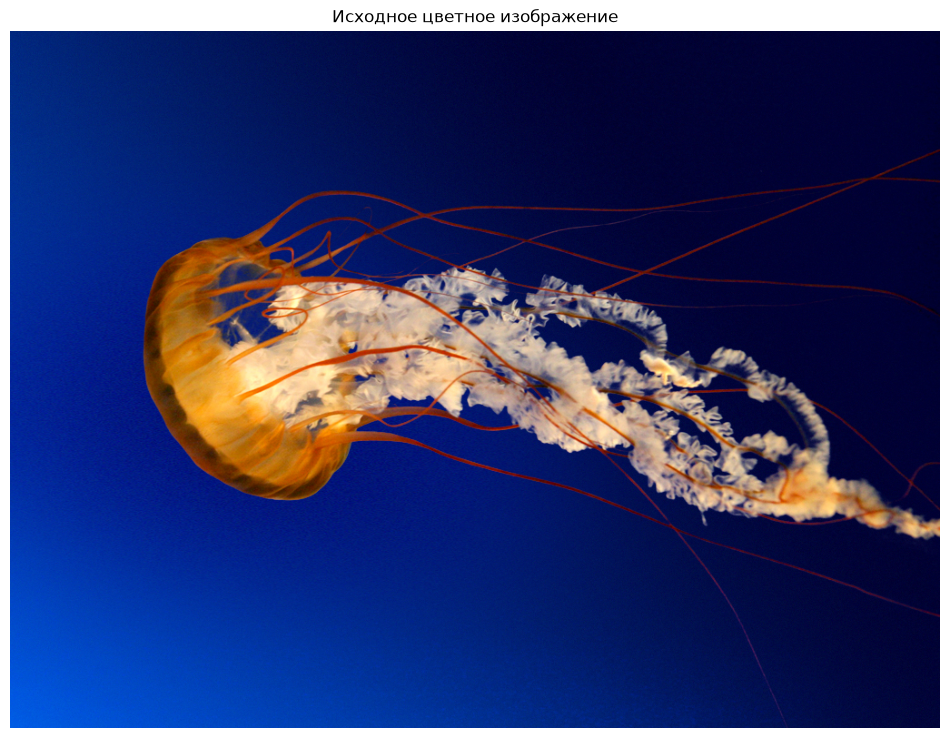

In [23]:
print(f'\nЦветное изображение: shape={img_color_arr.shape}')
show_image(img_color_arr, 'Исходное цветное изображение')

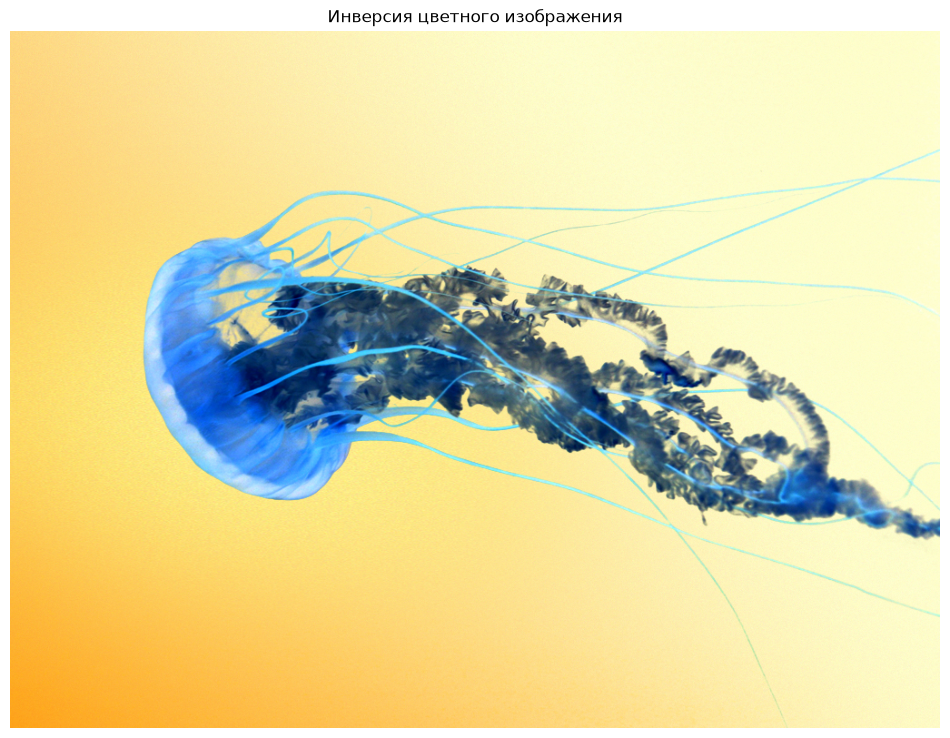

CPU times: total: 6.75 s
Wall time: 13.2 s


In [24]:
%%time
img_color_inv = send_to_server(server.color_inversion, img_color_arr)
show_image(img_color_inv, 'Инверсия цветного изображения')

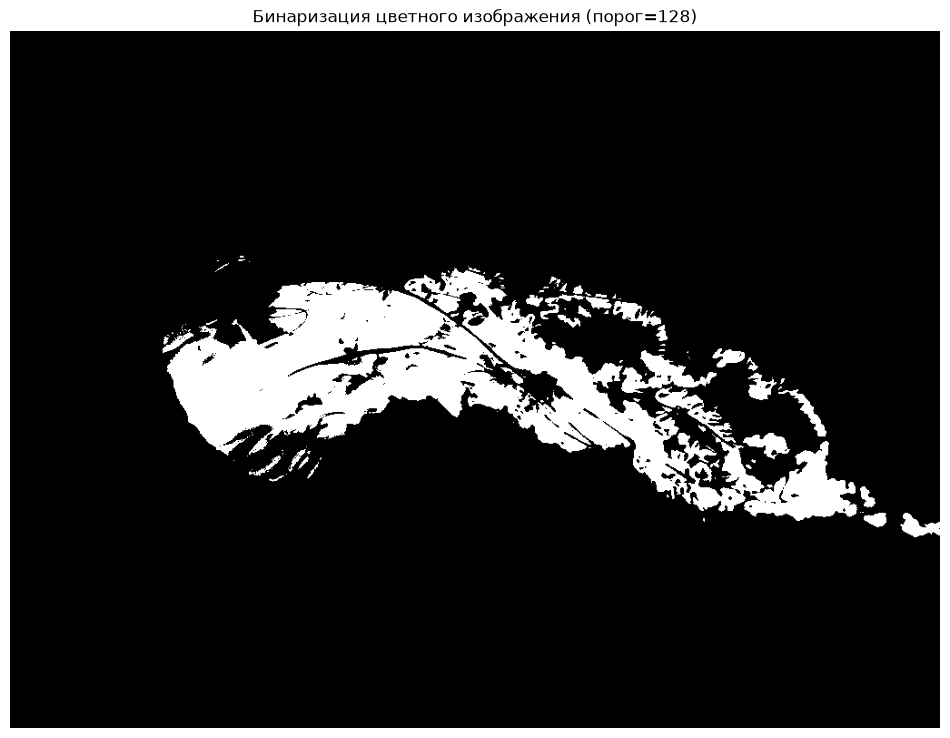

CPU times: total: 2.66 s
Wall time: 43.5 s


In [12]:
%%time
threshold = 128
img_color_bin = send_to_server(server.binarization, img_color_arr, threshold)
show_image(img_color_bin, f'Бинаризация цветного изображения (порог={threshold})')

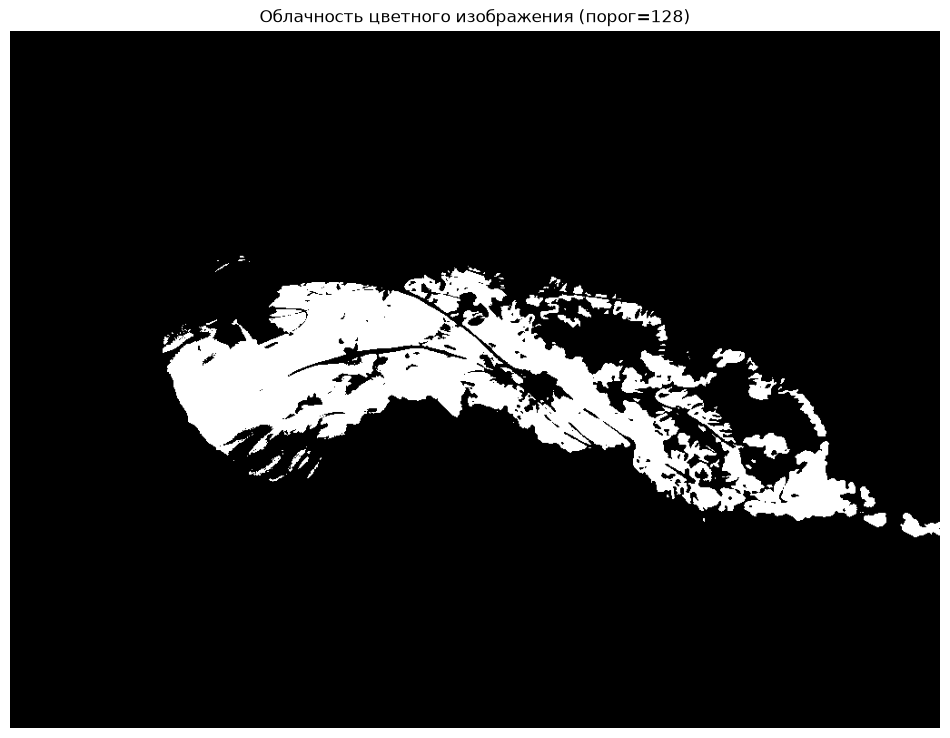

Порог: 128
Процент пикселей выше порога: 9.58%
CPU times: total: 2.67 s
Wall time: 47.5 s


In [9]:
%%time
threshold = 128
pimg = pickle.dumps(img_color_arr)
img_bin = xmlrpc.client.Binary(pimg)
result = server.binarization_cloud(img_bin, threshold)
img_color_cloud_bin = result[0]
percentage_color = result[1]
img_color_cloud_arr = pickle.loads(img_color_cloud_bin.data)

show_image(img_color_cloud_arr, f'Облачность цветного изображения (порог={threshold})')
print(f"Порог: {threshold}")
print(f"Процент пикселей выше порога: {percentage_color:.2f}%")

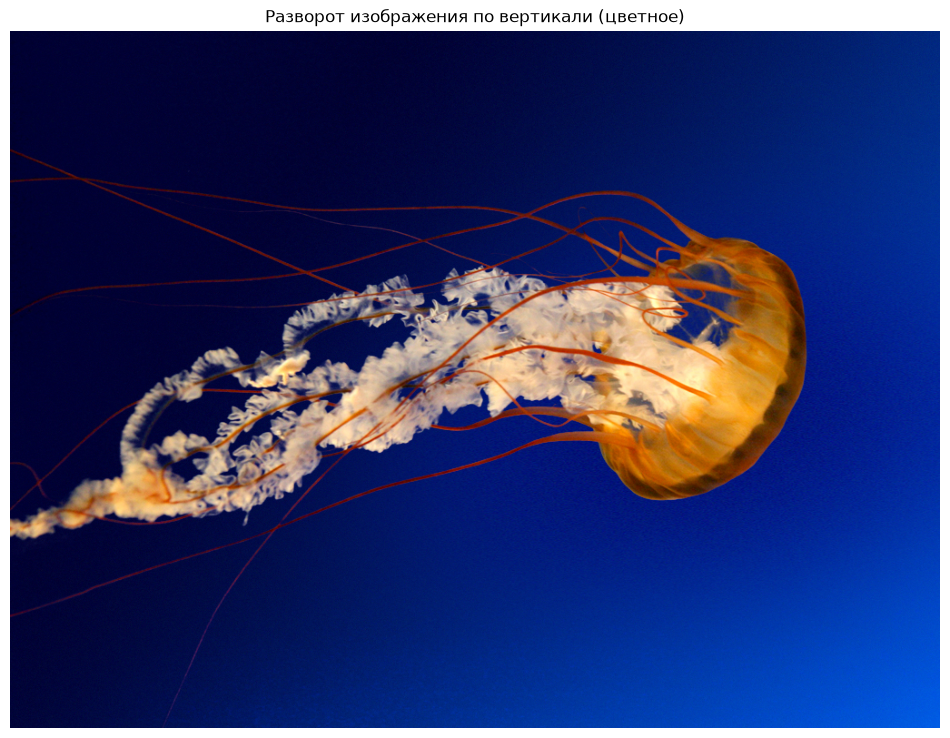

CPU times: total: 7.11 s
Wall time: 14 s


In [26]:
%%time
img_color_flip = send_to_server(server.vertical_flip, img_color_arr)
show_image(img_color_flip, 'Разворот изображения по вертикали (цветное)')

In [11]:
print("Тестирование обработки монохромного изображения")

img_mono = Image.open('11.bmp')
img_mono_arr = array(img_mono)

Тестирование обработки монохромного изображения



Монохромное изображение: shape=(780, 780), dtype=uint8


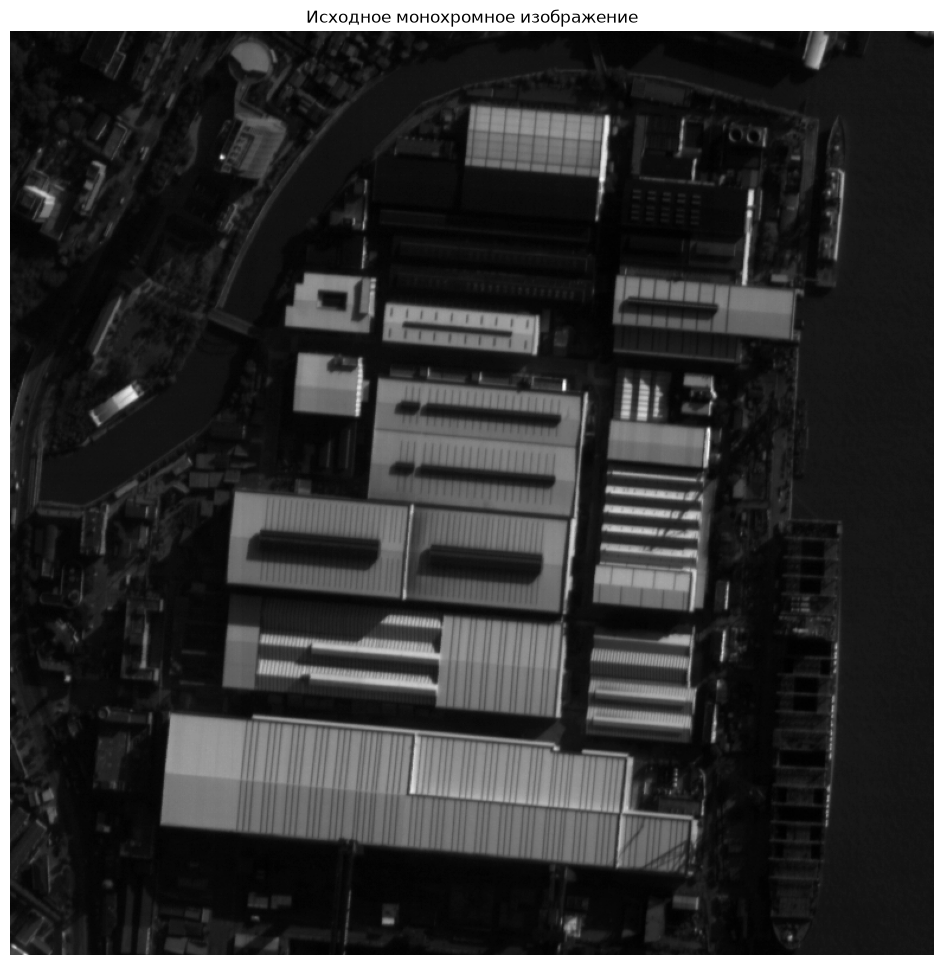

In [11]:
print(f'\nМонохромное изображение: shape={img_mono_arr.shape}, dtype={img_mono_arr.dtype}')
show_image(img_mono_arr, 'Исходное монохромное изображение')

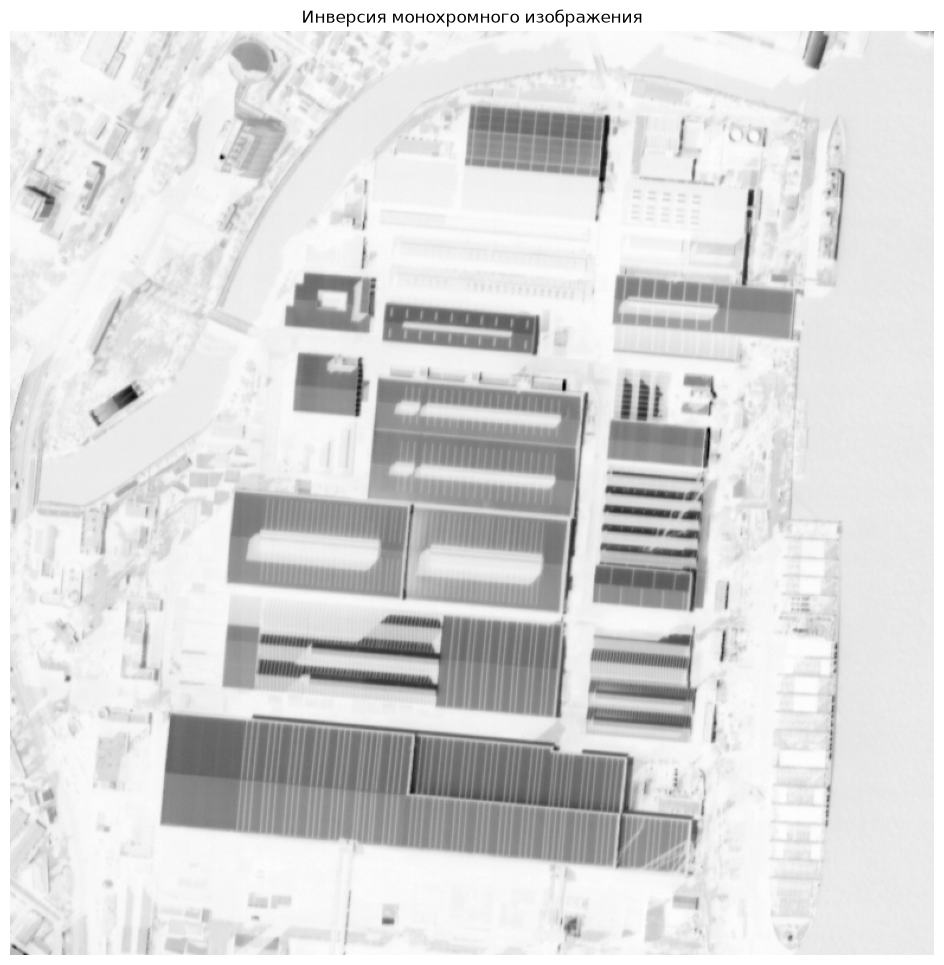

CPU times: total: 1.41 s
Wall time: 4.48 s


In [12]:
%%time
img_mono_inv = send_to_server(server.color_inversion, img_mono_arr)
show_image(img_mono_inv, 'Инверсия монохромного изображения')

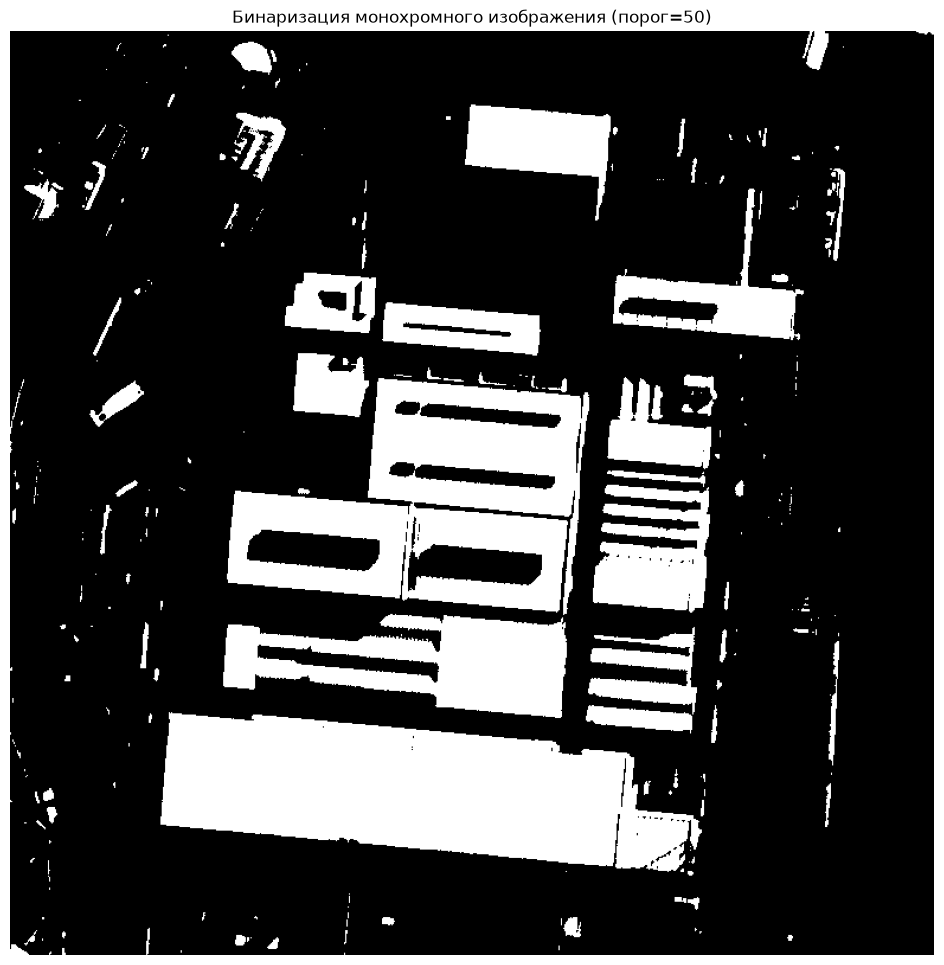

CPU times: total: 656 ms
Wall time: 1.52 s


In [27]:
%%time
threshold_mono = 50
img_mono_bin = send_to_server(server.binarization, img_mono_arr, threshold_mono)
show_image(img_mono_bin, f'Бинаризация монохромного изображения (порог={threshold_mono})')

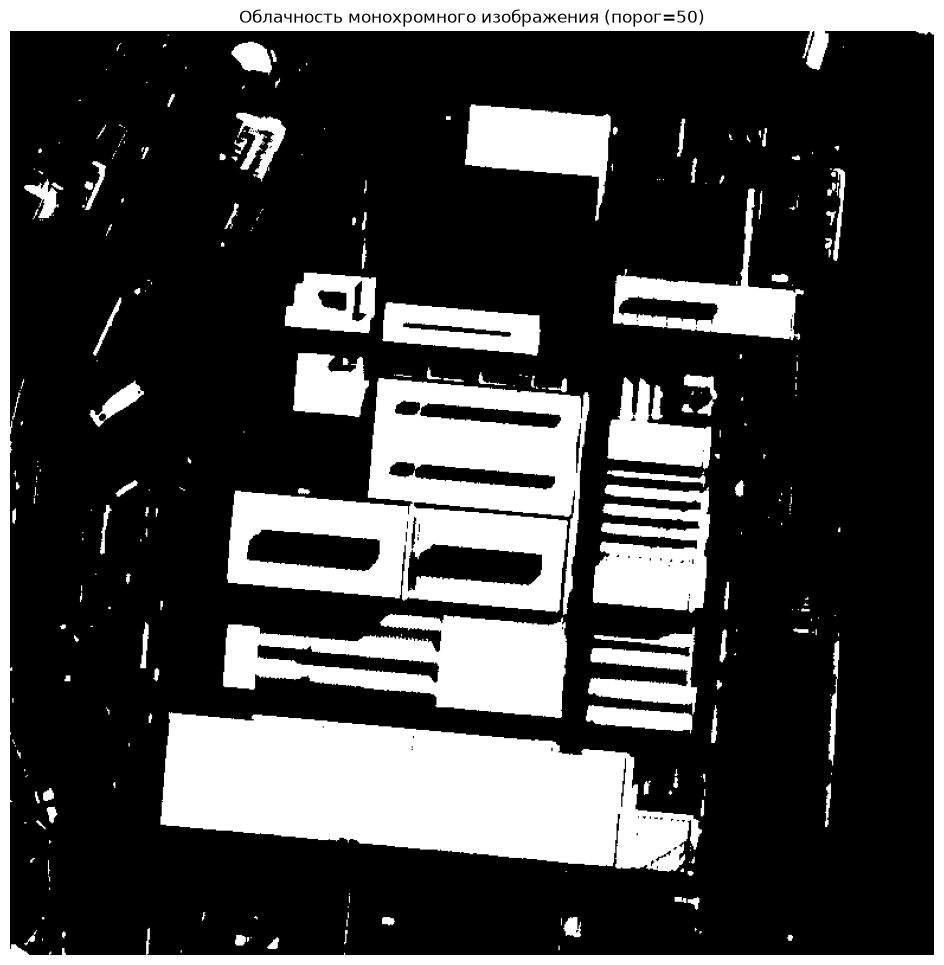

Порог: 50
Процент пикселей выше порога: 21.77%
CPU times: total: 1.16 s
Wall time: 2.23 s


In [12]:
%%time
threshold_mono = 50
pimg_mono = pickle.dumps(img_mono_arr)
img_bin_mono = xmlrpc.client.Binary(pimg_mono)
result = server.binarization_cloud(img_bin_mono, threshold_mono)
img_mono_cloud_bin = result[0]
percentage_mono = result[1]
img_mono_cloud_arr = pickle.loads(img_mono_cloud_bin.data)

show_image(img_mono_cloud_arr, f'Облачность монохромного изображения (порог={threshold_mono})')
print(f"Порог: {threshold_mono}")
print(f"Процент пикселей выше порога: {percentage_mono:.2f}%")

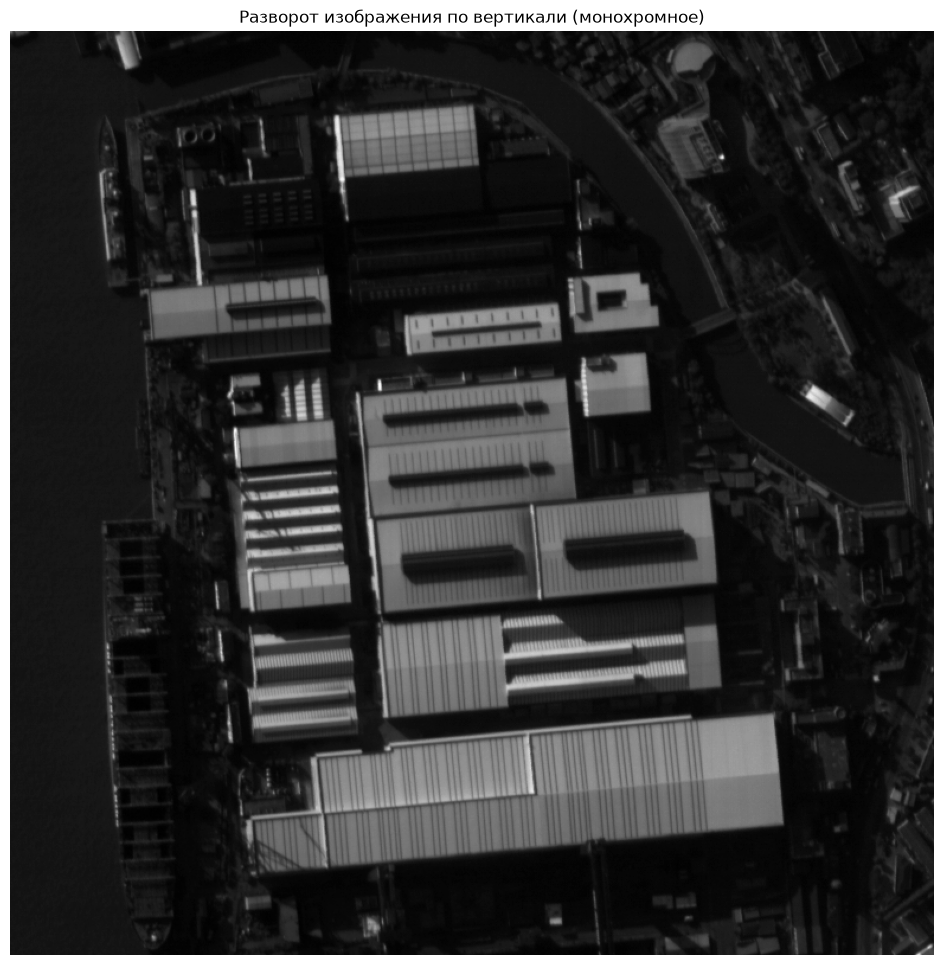

CPU times: total: 1.38 s
Wall time: 4.5 s


In [22]:
%%time
img_mono_flip = send_to_server(server.vertical_flip, img_mono_arr)
show_image(img_mono_flip, 'Разворот изображения по вертикали (монохромное)')

#### Работа с журналами

Фаза 1: генерация событий для создания первого архива

In [15]:
%%time
for i in range(150):
    server.ping()
    server.sum(i, i)

print("Фаза 1 завершена.")

Фаза 1 завершена.
CPU times: total: 688 ms
Wall time: 2.36 s


Фаза 2: события попадают в новый log.csv

In [22]:
%%time
for i in range(50):
    server.pow(2, i % 10)
    server.now()

print("Фаза 2 завершена.")

Фаза 2 завершена.
CPU times: total: 188 ms
Wall time: 895 ms


Фаза 3: разнообразные вызовы

In [24]:
%%time
for i in range(30):
    server.ping()
    server.type(i)
    server.black_list_check("Иванов", "Иван", "Иванович", "22.03.1989")

print("Фаза 3 завершена.")
print("\nНа сервере статистики созданы архивные файлы журнала.")

Фаза 3 завершена.

На сервере статистики созданы архивные файлы журнала.
CPU times: total: 141 ms
Wall time: 1.13 s


In [4]:
def show_full_log():
    """Получить и отобразить весь журнал событий."""
    log = stats_server.get_log()
    print(f"Всего записей: {len(log)}")
    
    # for event_type, timestamp in log:
    #     print(f"  {timestamp} | {event_type}")

    if len(log) > 0:
        print(f"Первая запись: {log[0]}")
        print(f"Последняя запись: {log[-1]}")
        print("\nПервые 5 записей:")
        for entry in log[:5]:
            print(f"   {entry[1]} | {entry[0]}")
        if len(log) > 5:
            print("...")
            print("Последние 5 записей:")
            for entry in log[-5:]:
                print(f"   {entry[1]} | {entry[0]}")
    
    return log

In [5]:
def show_log_by_type(event_type):
    """Получить срез журнала по типу события."""
    log = stats_server.get_log_by_type(event_type)
    print(f"Записей типа '{event_type}': {len(log)}")
    for et, ts in log:
        print(f"  {ts} | {et}")
    return log

In [6]:
def show_log_by_time(start_time, end_time):
    """Получить срез журнала по времени."""
    log = stats_server.get_log_by_time(start_time, end_time)
    print(f"Записей за период [{start_time} — {end_time}]: {len(log)}")
    
    # for et, ts in log:
    #     print(f"  {ts} | {et}")

    if len(log) > 0:
        print("Первые 5 записей:")
        for et, ts in log[:5]:
            print(f"   {ts} | {et}")
        if len(log) > 5:
            print("...")
            print("Последние 5 записей:")
            for et, ts in log[-5:]:
                print(f"   {ts} | {et}")
    
    return log

In [7]:
print("\nПолный журнал событий:")
full_log = show_full_log()


Полный журнал событий:
Всего записей: 46
Первая запись: ['black_list_check:Иванов Иван Иванович', '2026-10-01 19:26:15']
Последняя запись: ['test_pow', '2026-10-03 23:52:22']

Первые 5 записей:
   2026-10-01 19:26:15 | black_list_check:Иванов Иван Иванович
   2026-10-01 19:26:15 | black_list_check:Светлый Михаил Викторович
   2026-10-01 19:26:15 | black_list_check:Скалина Светлана Алексеевна
   2026-10-01 19:26:15 | black_list_check:ИВАНОВ иван Иванович
   2026-10-01 19:26:16 | black_list_check:петров ПЕТР петрович
...
Последние 5 записей:
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | test_sum
   2026-10-03 23:52:22 | test_pow


In [8]:
print("\nСрезы по типу события:")
event_types = ['ping', 'sum', 'pow', 'now', 'type', 'black_list_check',
               'color_inversion', 'binarization', 'binarization_cloud', 'vertical_flip']

for et in event_types:
    show_log_by_type(et)


Срезы по типу события:
Записей типа 'ping': 2
  2026-10-01 19:33:47 | ping
  2026-10-03 23:52:22 | ping
Записей типа 'sum': 0
Записей типа 'pow': 0
Записей типа 'now': 2
  2026-10-01 19:33:47 | now
  2026-10-03 23:52:22 | now
Записей типа 'type': 0
Записей типа 'black_list_check': 24
  2026-10-01 19:26:15 | black_list_check:Иванов Иван Иванович
  2026-10-01 19:26:15 | black_list_check:Светлый Михаил Викторович
  2026-10-01 19:26:15 | black_list_check:Скалина Светлана Алексеевна
  2026-10-01 19:26:15 | black_list_check:ИВАНОВ иван Иванович
  2026-10-01 19:26:16 | black_list_check:петров ПЕТР петрович
  2026-10-01 19:26:16 | black_list_check:Питров Петр Петрович
  2026-10-01 19:26:16 | black_list_check:Светлый Мехаил Викторович
  2026-10-01 19:26:16 | black_list_check:Склина Светлана Алексеевна
  2026-10-01 19:26:16 | black_list_check:Дорбынин Виталий Александрович
  2026-10-01 19:26:16 | black_list_check:Сидоров Алексей Петрович
  2026-10-01 19:26:16 | black_list_check:Кузнецов Мария С

In [9]:
# Получаем информацию о всех файлах
log_info = stats_server.get_log_info()

print("Архивные файлы:")
archives = log_info['archives']
if len(archives) > 0:
    for filename, start, end in archives:
        print(f"   {filename}")
        start_display = start if start else "начало времён"
        end_display = end if end else "до ротации"
        print(f"      диапазон: {start_display} - {end_display}")
else:
    print("   Архивов нет.")

print("\nТекущий файл:")
current = log_info['current']
if current:
    print(f"   {current[0]}")
    start_display = current[1] if current[1] else "начало времён"
    end_display = current[2] if current[2] else "сейчас"
    print(f"      диапазон: {start_display} - {end_display}")

Архивные файлы:
   log_20261001_190749.csv
      диапазон: начало времён - 2026-10-01 19:07:49
   log_20261001_190750.csv
      диапазон: 2026-10-01 19:07:49 - 2026-10-01 19:07:50
   log_20261001_190751.csv
      диапазон: 2026-10-01 19:07:50 - 2026-10-01 19:07:51
   log_20261001_190810.csv
      диапазон: 2026-10-01 19:07:51 - 2026-10-01 19:08:10
   log_20261001_190920.csv
      диапазон: 2026-10-01 19:08:10 - 2026-10-01 19:09:20
   log_20261001_191050.csv
      диапазон: 2026-10-01 19:09:20 - 2026-10-01 19:10:50
   log_20261001_192615.csv
      диапазон: 2026-10-01 19:10:50 - 2026-10-01 19:26:15

Текущий файл:
   log.csv
      диапазон: 2026-10-01 19:26:15 - сейчас


In [14]:
print("Тест 1: срез по всему диапазону")

# Определение самого широкого диапазона на основе информации о файлах
all_starts = []
all_ends = []

for filename, start, end in archives:
    # Если start пустой — это первый архив, берём "начало времён"
    if start:
        all_starts.append(start)
    else:
        all_starts.append("1970-01-01 00:00:00")
    
    if end:
        all_ends.append(end)

if current and current[2]:
    all_ends.append(current[2])

if len(all_starts) > 0 and len(all_ends) > 0:
    earliest = min(all_starts)
    latest = max(all_ends)
    
    print(f"Самый широкий диапазон: {earliest} - {latest}")
    
    slice_all = stats_server.get_log_by_time(earliest, latest)
    print(f"Записей в срезе: {len(slice_all)}")
    
    # Сравнение с текущим log.csv
    full_log = stats_server.get_log()
    print(f"Записей в текущем log.csv: {len(full_log)}")
    print(f"Разница (архивные записи): {len(slice_all) - len(full_log)}")
    
    print("\nВывод:")
    print("- Функция get_log() возвращает только текущий log.csv")
    print("- Функция get_log_by_time() читает и архивы, и текущий файл")
    
    if len(slice_all) > 0:
        print(f"\nПервая запись среза: {slice_all[0]}")
        print(f"Последняя запись среза: {slice_all[-1]}")
else:
    print("Журнал пуст.")

Тест 1: срез по всему диапазону
Самый широкий диапазон: 1970-01-01 00:00:00 - 2026-10-01 19:26:15
Записей в срезе: 704
Записей в текущем log.csv: 46
Разница (архивные записи): 658

Вывод:
- Функция get_log() возвращает только текущий log.csv
- Функция get_log_by_time() читает и архивы, и текущий файл

Первая запись среза: ['ping', '2026-10-01 19:04:55']
Последняя запись среза: ['black_list_check:ИВАНОВ иван Иванович', '2026-10-01 19:26:15']


In [12]:
print("Тест 2: срез по архивному файлу")

if len(archives) > 0:
    # архив и его диапазон
    arch_filename, arch_start, arch_end = archives[2]
    
    print(f"Архив: {arch_filename}")
    print(f"Диапазон: {arch_start} - {arch_end}")
    
    slice_arch = stats_server.get_log_by_time(arch_start, arch_end)
    
    print(f"Записей в срезе: {len(slice_arch)}")
    
    if len(slice_arch) > 0:
        print("\nПервые 5 записей:")
        for entry in slice_arch[:5]:
            print(f"   {entry[1]} | {entry[0]}")
        if len(slice_arch) > 5:
            print("...")
            print("Последние 5 записей:")
            for entry in slice_arch[-5:]:
                print(f"   {entry[1]} | {entry[0]}")
else:
    print("Архивов нет. Запустите блок создания архивов.")

Тест 2: срез по архивному файлу
Архив: log_20261001_190751.csv
Диапазон: 2026-10-01 19:07:50 - 2026-10-01 19:07:51
Записей в срезе: 111

Первые 5 записей:
   2026-10-01 19:07:50 | test_sum
   2026-10-01 19:07:50 | ping
   2026-10-01 19:07:50 | test_sum
   2026-10-01 19:07:50 | ping
   2026-10-01 19:07:50 | test_sum
...
Последние 5 записей:
   2026-10-01 19:07:51 | test_sum
   2026-10-01 19:07:51 | ping
   2026-10-01 19:07:51 | test_sum
   2026-10-01 19:07:51 | ping
   2026-10-01 19:07:51 | test_sum


In [15]:
print("Тест 3: срез по текущему файлу log.csv")

if current and current[0]:
    curr_filename, curr_start, curr_end = current
    
    print(f"Текущий файл: {curr_filename}")
    start_display = curr_start if curr_start else "начало времён"
    end_display = curr_end if curr_end else "сейчас"
    print(f"Диапазон: {start_display} - {end_display}")
    
    # Определение реального диапазона для среза
    from datetime import datetime
    slice_start = curr_start if curr_start else "1970-01-01 00:00:00"
    slice_end = curr_end if curr_end else datetime.now().strftime("%Y-%m-%d %H:%M:%S")
    
    # Диапазон в пределах текущего файла
    slice_current = stats_server.get_log_by_time(slice_start, slice_end)
    
    print(f"Записей в срезе: {len(slice_current)}")
    
    # Сравнение с get_log()
    full_log = stats_server.get_log()
    print(f"Записей через get_log(): {len(full_log)}")
    
    if len(slice_current) > 0:
        print("\nПервые 5 записей:")
        for entry in slice_current[:5]:
            print(f"   {entry[1]} | {entry[0]}")
        if len(slice_current) > 5:
            print("...")
            print("Последние 5 записей:")
            for entry in slice_current[-5:]:
                print(f"   {entry[1]} | {entry[0]}")
else:
    print("Текущий файл пуст или информация недоступна.")

Тест 3: срез по текущему файлу log.csv
Текущий файл: log.csv
Диапазон: 2026-10-01 19:26:15 - сейчас
Записей в срезе: 46
Записей через get_log(): 46

Первые 5 записей:
   2026-10-01 19:26:15 | black_list_check:Иванов Иван Иванович
   2026-10-01 19:26:15 | black_list_check:Светлый Михаил Викторович
   2026-10-01 19:26:15 | black_list_check:Скалина Светлана Алексеевна
   2026-10-01 19:26:15 | black_list_check:ИВАНОВ иван Иванович
   2026-10-01 19:26:16 | black_list_check:петров ПЕТР петрович
...
Последние 5 записей:
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | show_type
   2026-10-03 23:52:22 | test_sum
   2026-10-03 23:52:22 | test_pow
